# Transition 2040: Daten → Berechnungen → Ausgaben

Redaktioneller Modellstand 2026. **Ausgangsjahr 2020**, ausdrücklich vom Auftraggeber gewählt. Die UBA-Zahlen bleiben unverändert; Varianten liefern keine freigegebene Mobilitätsgutschrift.

Quellen: REP-0880 (Copyright 2024, Titelblatt 2023), Tabelle A S. 7, Tabelle 15 S. 60, Tabelle 16 S. 63. Vergleichsszenarien und Fundstellen stehen in `Daten/sektorenmodell/sources.csv`. Die Primärquelle Streicher (2010), Schneider (2020) und die Kalibrierung 2023 werden im Bericht getrennt zitiert.

Ausführung: Repository klonen, Python mit pandas, plotly, nbformat, nbclient, ipykernel und ipywidgets bereitstellen; alle Zellen ausführen. Der Notebook-Pfad ist absichtlich im Handoff-Verzeichnis versioniert. Plotly-JSON benötigt eine Plotly-fähige Notebook-Oberfläche; die gespeicherte PNG-Vorschau und die offlinefähige HTML-Datei funktionieren unabhängig davon.


In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, clear_output
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / '_quarto.yml').exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from Berechnungen.sektorenmodell.sankey import calculation, figure, export_comparison
from Berechnungen.sektorenmodell.model import validate, DATA, DEMAND, NAMES
display(pd.DataFrame(validate()))


,scenario,eev_rounding_difference_pj,generation_rounding_difference_pj,electricity_rounding_difference_pj,electricity_balance_residual_pj
0,transition_2040,0.0,0.0,2.0,0.0
1,wem_2025,-1.0,0.0,-1.0,1.0
2,wam_2025,0.0,0.0,0.0,2.0
3,wem_2023,0.0,-1.0,-1.0,0.0
4,wam_2023,-1.0,0.0,0.0,0.0


In [2]:
sources = pd.read_csv(DATA / 'sources.csv')
baseline = pd.read_csv(DATA / 'baseline_energy.csv')
display(sources)
display(baseline[baseline.year == 2020])
for filename in ['endenergie_2040.csv', 'strombedarf_2040.csv', 'stromerzeugung_2040.csv']:
    print(filename)
    display(pd.read_csv(DATA / filename).query("scenario == 'transition_2040'"))


,source_id,bibkey,url,scope
0,TRANSITION,uba2023transition,https://www.umweltbundesamt.at/fileadmin/site/...,Tab. A S. 7; Tab. 15 S. 60; Tab. 16 S. 63
1,UBA2023,uba2023szenarien,https://www.umweltbundesamt.at/fileadmin/site/...,Tab. 12 S. 39
2,UBA2023_SUM,uba2023zusammenfassung,https://www.umweltbundesamt.at/fileadmin/site/...,Tab. B S. 5; Tab. D S. 8
3,UBA2025,uba2025szenarien,https://www.umweltbundesamt.at/fileadmin/site/...,Tab. B S. 10; Tab. E S. 12; Tab. 18 S. 62
4,SCHNEIDER2020,schneider2020lokal,NaN,Nutzeroriginal 10 Seiten; Abschn. 3.1.4 und 5....
5,SCHNEIDER2023,schneider2023context,https://doi.org/10.3390/buildings13051210,Abschn. 6.1 und 6.2; Tab. 6 und 8 und 9


,year,metric,value_pj,energy_basis,source_id,source_location,notes
0,2020,hydro,151,electricity_generation,TRANSITION,"Tabelle 16, S. 63",NaN
1,2020,wind,24,electricity_generation,TRANSITION,"Tabelle 16, S. 63",NaN
2,2020,pv,7,electricity_generation,TRANSITION,"Tabelle 16, S. 63",NaN
3,2020,biomass,17,electricity_generation,TRANSITION,"Tabelle 16, S. 63",NaN
4,2020,geothermal,0,electricity_generation,TRANSITION,"Tabelle 16, S. 63",NaN
5,2020,hydrogen_electricity,0,electricity_generation,TRANSITION,"Tabelle 16, S. 63","Quellwert Strich, für Differenzdarstellung als..."
6,2020,fossil,50,electricity_generation,TRANSITION,"Tabelle 16, S. 63",NaN
7,2020,published_total,249,electricity_generation,TRANSITION,"Tabelle 16, S. 63",NaN
8,2020,net_imports,8,electricity_generation,TRANSITION,"Tabelle 16, S. 63",NaN
9,2020,verkehr,11,electricity_demand,TRANSITION,"Tabelle 15, S. 60",NaN


endenergie_2040.csv


,scenario,year,metric,value_pj,energy_basis,source_id,source_location
10,transition_2040,2040,verkehr,151,energetic_final,TRANSITION,"Tabelle A, S. 7"
11,transition_2040,2040,industrie,260,energetic_final,TRANSITION,"Tabelle A, S. 7"
12,transition_2040,2040,gebaeude,300,energetic_final,TRANSITION,"Tabelle A, S. 7"
13,transition_2040,2040,landwirtschaft,11,energetic_final,TRANSITION,"Tabelle A, S. 7"
14,transition_2040,2040,eev_published_total,722,energetic_final,TRANSITION,"Tabelle A, S. 7"


strombedarf_2040.csv


,scenario,year,metric,value_pj,energy_basis,source_id,source_location
16,transition_2040,2040,verkehr,90,electricity_demand,TRANSITION,"Tabelle 15, S. 60"
17,transition_2040,2040,gebaeude,108,electricity_demand,TRANSITION,"Tabelle 15, S. 60"
18,transition_2040,2040,landwirtschaft,4,electricity_demand,TRANSITION,"Tabelle 15, S. 60"
19,transition_2040,2040,industrie,140,electricity_demand,TRANSITION,"Tabelle 15, S. 60"
20,transition_2040,2040,verbrauch_sektor_energie,34,electricity_demand,TRANSITION,"Tabelle 15, S. 60"
21,transition_2040,2040,transportverluste,19,electricity_demand,TRANSITION,"Tabelle 15, S. 60"
22,transition_2040,2040,umwandlungseinsatz,57,electricity_demand,TRANSITION,"Tabelle 15, S. 60"
23,transition_2040,2040,electricity_demand_published_total,450,electricity_demand,TRANSITION,"Tabelle 15, S. 60"


stromerzeugung_2040.csv


,scenario,year,metric,value_pj,energy_basis,source_id,source_location,notes
18,transition_2040,2040,fossil,1,electricity_generation_or_net_import,TRANSITION,"Tabelle 16, S. 63",NaN
19,transition_2040,2040,hydro,173,electricity_generation_or_net_import,TRANSITION,"Tabelle 16, S. 63",NaN
20,transition_2040,2040,biomass,21,electricity_generation_or_net_import,TRANSITION,"Tabelle 16, S. 63",NaN
21,transition_2040,2040,geothermal,4,electricity_generation_or_net_import,TRANSITION,"Tabelle 16, S. 63",NaN
22,transition_2040,2040,pv,149,electricity_generation_or_net_import,TRANSITION,"Tabelle 16, S. 63",NaN
23,transition_2040,2040,wind,105,electricity_generation_or_net_import,TRANSITION,"Tabelle 16, S. 63",NaN
24,transition_2040,2040,hydrogen_electricity,4,electricity_generation_or_net_import,TRANSITION,"Tabelle 16, S. 63",NaN
25,transition_2040,2040,generation_published_total,457,electricity_generation_or_net_import,TRANSITION,"Tabelle 16, S. 63",NaN
26,transition_2040,2040,net_imports,-7,electricity_generation_or_net_import,TRANSITION,"Tabelle 16, S. 63",Negative Nettoimporte bedeuten Nettoexporte.


## Unveränderte UBA-Referenz

Stromerzeugung 249 → 457 PJ/a; publizierter Strombedarf 257 → 450 PJ/a; Endenergie 1.053 → 722 PJ/a. Die gerundeten Sektorkomponenten ergeben 330 statt 331 PJ Endenergieminderung und 452 statt 450 PJ Strombedarf. Diese Quellendifferenzen bleiben erhalten. Jahresertragszuwachs ist keine Aussage über MW, Bruttoinvestitionen, saisonale Deckung oder gesicherte Leistung.


,scenario,baseline_year,energy_basis,metric,baseline_pj,target_pj,change_pj,increase_pj,reduction_pj
0,transition_2040,2020,electricity_generation,hydro,151.0,173.0,22.0,22.0,0.0
1,transition_2040,2020,electricity_generation,wind,24.0,105.0,81.0,81.0,0.0
2,transition_2040,2020,electricity_generation,pv,7.0,149.0,142.0,142.0,0.0
3,transition_2040,2020,electricity_generation,biomass,17.0,21.0,4.0,4.0,0.0
4,transition_2040,2020,electricity_generation,geothermal,0.0,4.0,4.0,4.0,0.0
5,transition_2040,2020,electricity_generation,hydrogen_electricity,0.0,4.0,4.0,4.0,0.0
6,transition_2040,2020,electricity_generation,fossil,50.0,1.0,-49.0,0.0,49.0
7,transition_2040,2020,electricity_demand,verkehr,11.0,90.0,79.0,79.0,0.0
8,transition_2040,2020,electricity_demand,gebaeude,107.0,108.0,1.0,1.0,0.0
9,transition_2040,2020,electricity_demand,industrie,98.0,140.0,42.0,42.0,0.0


Rest gegenüber Strombedarfskomponenten [PJ/a]: -2.0
Neue Mobilitätsgutschrift: None


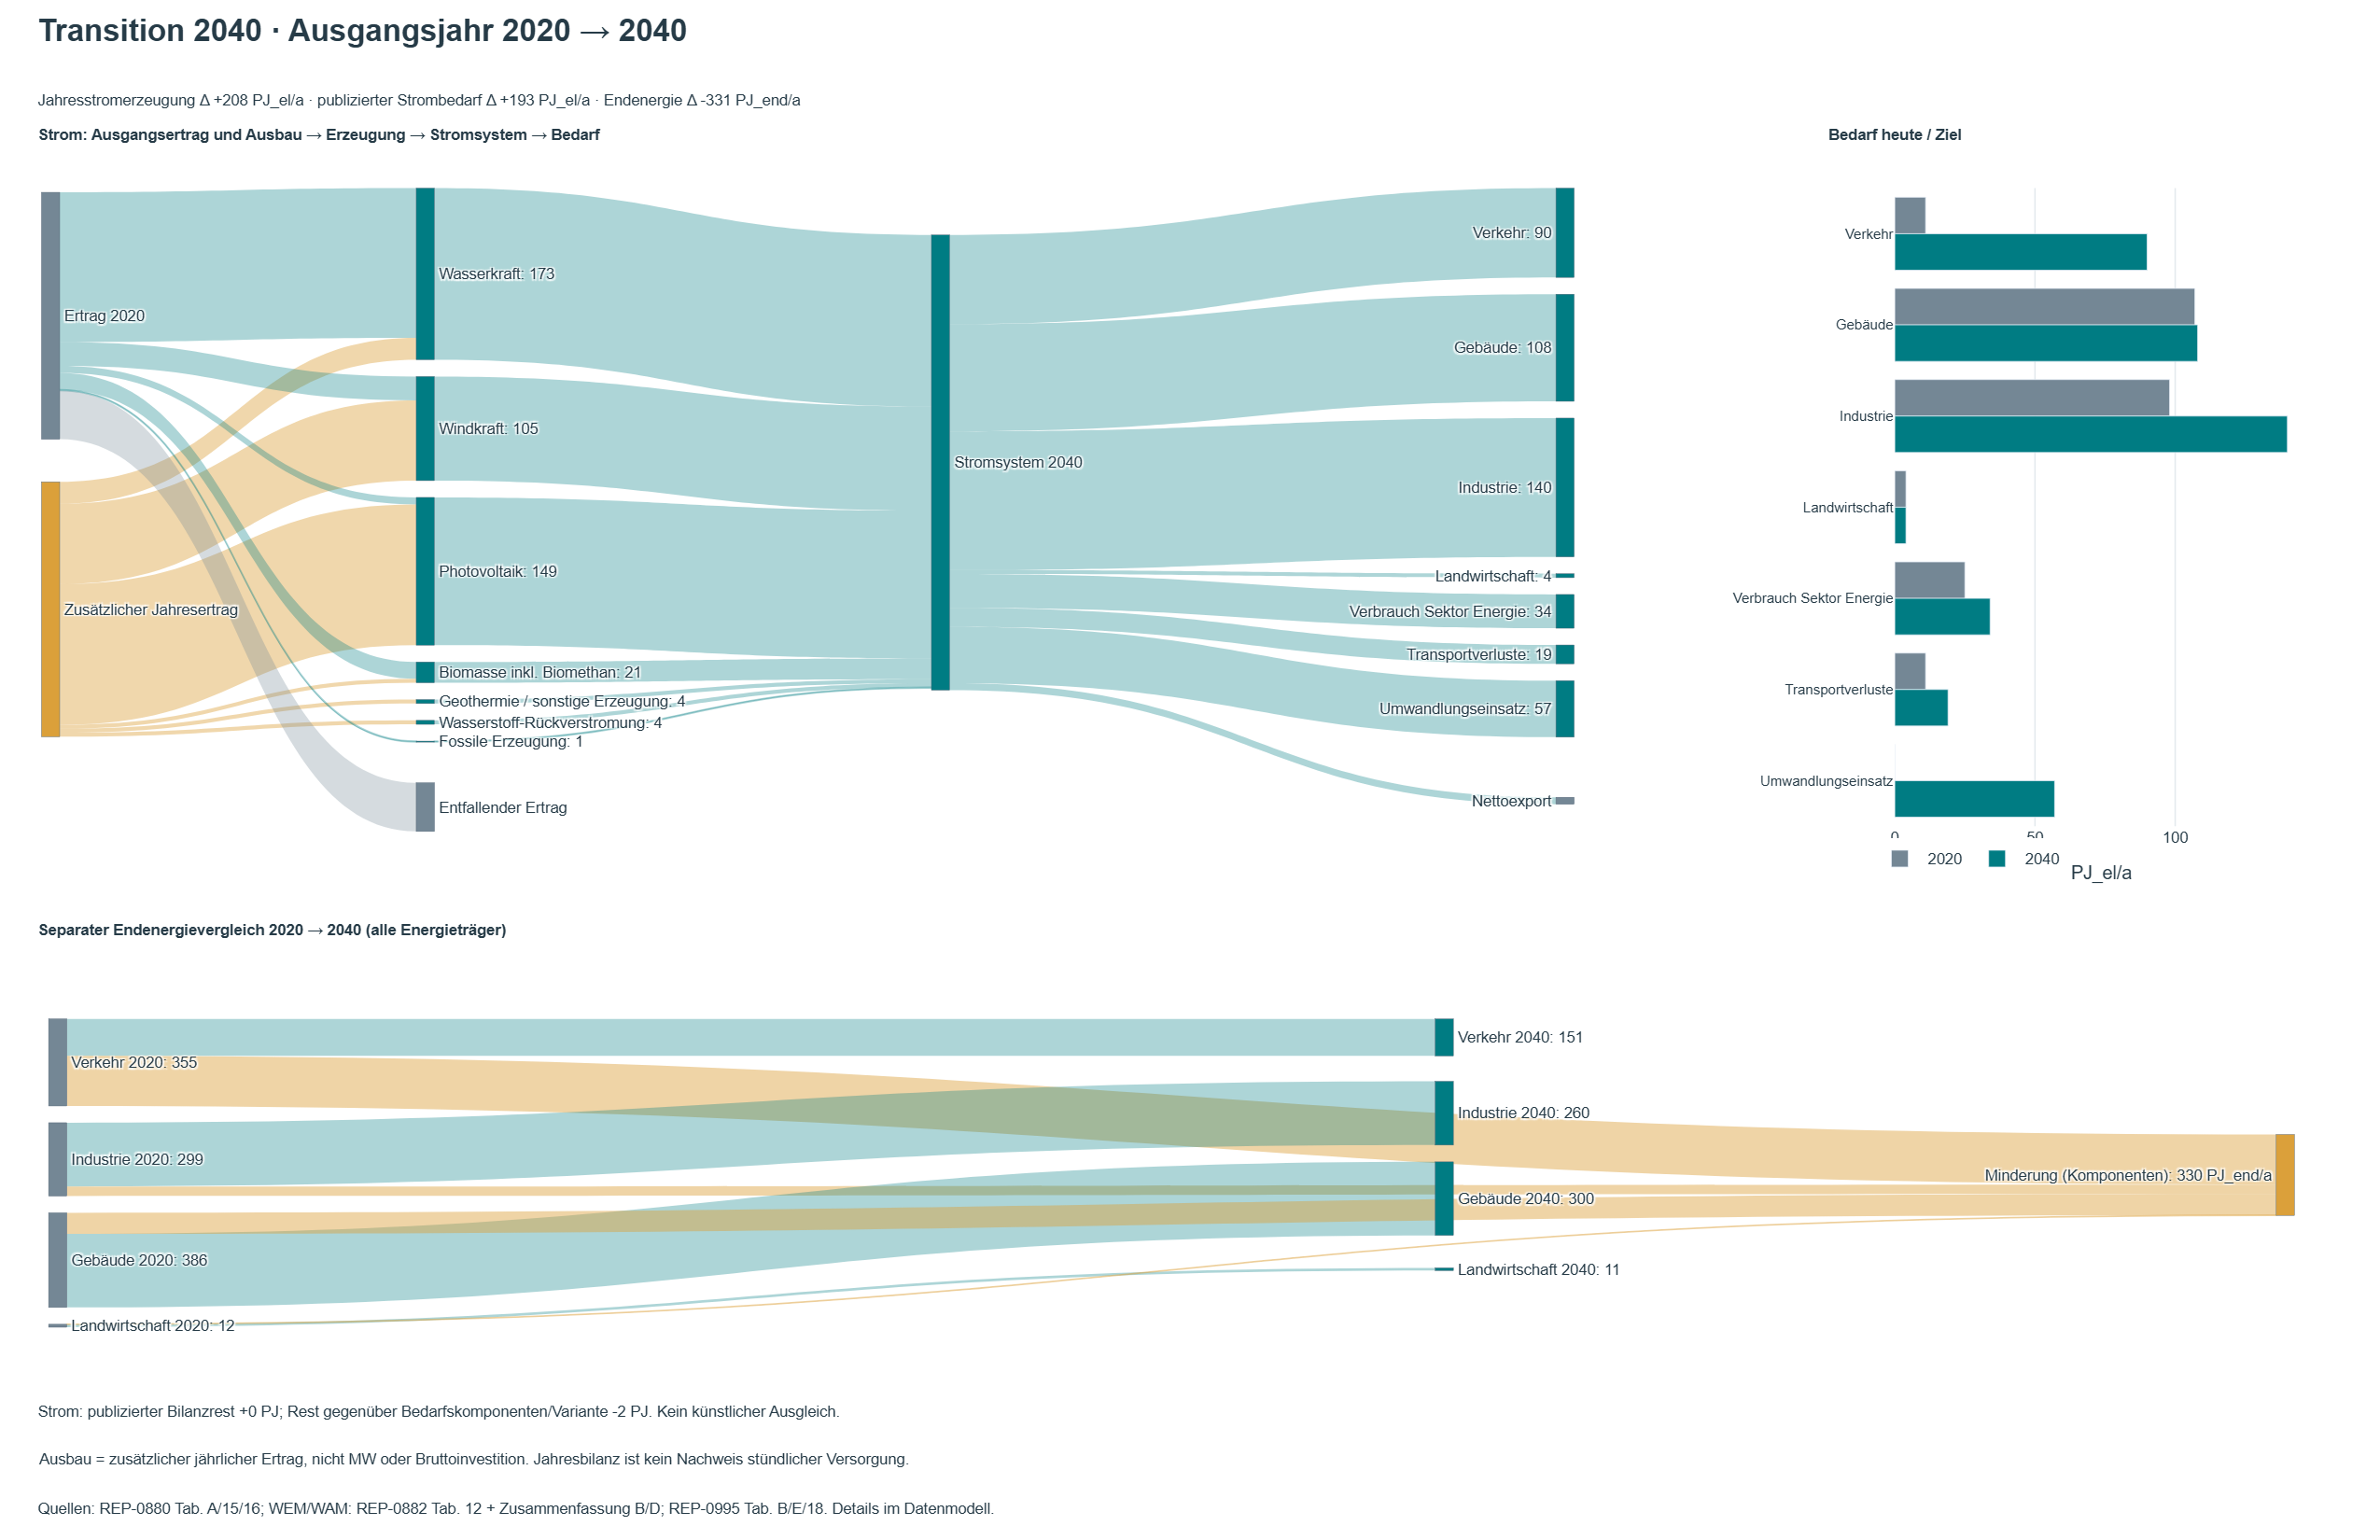

In [3]:
reference = calculation()
display(pd.DataFrame(reference['comparison']))
print('Rest gegenüber Strombedarfskomponenten [PJ/a]:', reference['electricity_residual_pj'])
print('Neue Mobilitätsgutschrift:', reference['new_mobility_credit'])
display(Image(filename=str(ROOT / 'Abbildungen/transition_sankey.png'), width=1200))


## Stellschrauben – ausdrücklich gekennzeichnete Varianten

Die Auswahlfelder sind zunächst **inaktiv**, nicht als empirische Vorgabe gesetzt. Erst durch Aktivierung werden PV beziehungsweise Verkehr aufgeteilt. PV zentral + dezentral = 100 %. MIV und ÖV sind Anteile am **elektrischen Energiebedarf des gesamten Verkehrs**, keine Wege- oder Personenkilometeranteile. Der Rest bleibt „übriger Verkehr“; MIV + ÖV dürfen 100 % nicht überschreiten. Es entsteht keine Zuordnung von Erzeugern zu bevorzugten Sektoren.

Zusätzliche Einsparungen beziehen sich auf den bereits projizierten **Strombedarf 2040**, nicht erneut auf 2020. Die publizierte Endenergieprojektion bleibt unverändert, weil keine technologiebezogene Substitutionsrechnung hinterlegt ist. Eine neue Bedarfsvariante bei fixierter Erzeugung kann Überschüsse erzeugen; diese werden als Bilanzrest und nicht als automatischer Export oder Gutschrift ausgegeben. Eine Annahmenbegründung ist Pflicht, sobald eine Variante aktiviert wird.


In [4]:
import ipywidgets as w
scenario = w.Dropdown(options=['transition_2040','wem_2025','wam_2025','wem_2023','wam_2023'], description='Szenario')
year = w.Dropdown(options=[2020,2023], value=2020, description='Ausgangsjahr')
pv_on = w.Checkbox(value=False, description='PV-Zuordnung aktiv')
pv = w.FloatSlider(value=1, min=0, max=1, step=.05, description='PV dezentral', readout_format='.0%')
traffic_on = w.Checkbox(value=False, description='Verkehrsaufteilung aktiv')
miv = w.FloatSlider(value=0, min=0, max=1, step=.05, description='MIV', readout_format='.0%')
ov = w.FloatSlider(value=0, min=0, max=1, step=.05, description='ÖV', readout_format='.0%')
saving_controls = {k:w.FloatSlider(value=0, min=0, max=1, step=.05, description=NAMES[k], readout_format='.0%', style={'description_width':'200px'}, layout=w.Layout(width='600px')) for k in DEMAND}
source = w.Textarea(value='', description='Begründung', placeholder='Quelle oder ausdrücklich eigene redaktionelle Annahme')
run = w.Button(description='Variante berechnen', button_style='primary')
export = w.Button(description='Variante exportieren')
out = w.Output()
def selected():
    return calculation(scenario.value, year.value,
        pv_decentral_share=pv.value if pv_on.value else None,
        transport_split={'miv':miv.value,'ov':ov.value} if traffic_on.value else None,
        savings={k:v.value for k,v in saving_controls.items()}, assumption_source=source.value.strip() or None)
def render_variant(_=None):
    with out:
        clear_output(wait=True)
        try:
            r = selected()
            figure(r).show(renderer='plotly_mimetype')
            display(pd.DataFrame(r['comparison']))
            print('Rest zur Bedarfsvariante [PJ/a]:', r['electricity_residual_pj'])
            print('Keine neue Mobilitätsgutschrift; Annahme:', r['assumption_source'])
        except ValueError as error: print(error)
def export_variant(_=None):
    with out:
        try:
            r = selected()
            from datetime import datetime, timezone
            dest = ROOT / '.local/transition-varianten' / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
            dest.mkdir(parents=True)
            (dest/'rechnung.json').write_text(json.dumps(r, ensure_ascii=False, indent=2), encoding='utf-8')
            export_comparison(r, dest/'vergleich.csv')
            figure(r).write_html(dest/'sankey.html', include_plotlyjs=True)
            print('Export einschließlich Annahmen:', dest)
        except ValueError as error: print(error)
run.on_click(render_variant)
export.on_click(export_variant)
display(w.VBox([scenario, year, pv_on, pv, traffic_on, miv, ov, *saving_controls.values(), source, w.HBox([run,export]), out]))


## Prüfrechnung und reproduzierbare Ausgaben

Die folgende Variante ist ausschließlich eine technische Prüfrechnung: 100 % dezentrale PV, 60 % MIV, 30 % ÖV, 10 % übriger Verkehr; zusätzliche 10 % Stromminderung im Gebäudesektor. **Diese Werte sind keine Empfehlung oder neue Allokationsregel.** Die Anteile illustrieren die Parametergrenzen. Produktionsausgaben entstehen aus `python -m Berechnungen.sektorenmodell.sankey --static`; die Referenztabellen aus `python Berechnungen/sektorenmodell/generate.py`.


In [5]:
example = calculation(pv_decentral_share=1, transport_split={'miv':.6,'ov':.3}, savings={'gebaeude':.1}, assumption_source='Technischer Test, keine normative Festlegung')
assert example['demand']['gebaeude'] == .9 * reference['demand']['gebaeude']
assert example['generation'] == reference['generation']
assert example['endenergy'] == reference['endenergy']
assert example['new_mobility_credit'] is None
display(pd.DataFrame(example['comparison']).query("energy_basis == 'electricity_demand'"))
print('Referenzdateien: Abbildungen/transition_sankey.html und Daten/sektorenmodell/transition_2020_2040_comparison.csv')


,scenario,baseline_year,energy_basis,metric,baseline_pj,target_pj,change_pj,increase_pj,reduction_pj
7,transition_2040,2020,electricity_demand,verkehr,11.0,90.0,79.0,79.0,0.0
8,transition_2040,2020,electricity_demand,gebaeude,107.0,97.2,-9.8,0.0,9.8
9,transition_2040,2020,electricity_demand,industrie,98.0,140.0,42.0,42.0,0.0
10,transition_2040,2020,electricity_demand,landwirtschaft,4.0,4.0,0.0,0.0,0.0
11,transition_2040,2020,electricity_demand,verbrauch_sektor_energie,25.0,34.0,9.0,9.0,0.0
12,transition_2040,2020,electricity_demand,transportverluste,11.0,19.0,8.0,8.0,0.0
13,transition_2040,2020,electricity_demand,umwandlungseinsatz,0.0,57.0,57.0,57.0,0.0


Referenzdateien: Abbildungen/transition_sankey.html und Daten/sektorenmodell/transition_2020_2040_comparison.csv
